In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm

warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

In [2]:
%load_ext autoreload
%autoreload 2

## Load Data

In [3]:
datafolder = "../data"
spadl_h5   = os.path.join(datafolder, "women-statsbomb3.h5")   

In [4]:
# ── Load combined long-format feature table (men + women, all tournaments) 
long_df = pd.read_hdf(spadl_h5, "combined_features_long")

# ── Load EFA tempo index and append as an extra metric row 
efa_df = pd.read_hdf(spadl_h5, "efa_tempo_index")[
    ["game_id", "possession", "possession_team_id", "tournament", "gender", "TI_horst"] #TI_efa
].copy()

# z-score TI_efa globally (already ~unit-variance but centre it like the others)
efa_df["value"] = efa_df["TI_horst"]
efa_df["value_z"] = (efa_df["value"] - efa_df["value"].mean()) / efa_df["value"].std(ddof=0)
efa_df["metric"] = "TI_horst"
# carry minimal ID columns that match long_df
efa_long = efa_df[["game_id", "possession", "possession_team_id",
                    "gender", "tournament", "metric", "value", "value_z"]].copy()

# Merge season / competition IDs back for efa rows
combined_wide = pd.read_hdf(spadl_h5, "combined_features")[
    ["game_id", "season_id", "competition_id", "period_id"]
].drop_duplicates("game_id")
efa_long = efa_long.merge(combined_wide, on="game_id", how="left")

long_df = pd.concat([long_df, efa_long], ignore_index=True)

print(f"Long-format rows total  : {len(long_df):,}")
print(long_df.groupby("metric")["value"].agg(["count","mean","std"]).round(3).to_string())

Long-format rows total  : 332,686
                                      count    mean    std
metric                                                    
TI_horst                              39995  -0.000  1.000
baseline_meters_per_second            42904   8.947  2.920
baseline_meters_per_touch_per_second  42445   1.782  2.402
baseline_passes_per_min               43773  19.265  8.051
baseline_time_to_pass                 38446   3.475  1.429
distance_per_second                   42904   8.947  2.920
passes_per_minute                     43773  19.265  8.051
time_to_pass                          38446   3.475  1.429


## Data Preparation for LMM

In [5]:
# ── Metric sets 
LATENT  = ["TI_horst"]

BASELINE = [
    "baseline_passes_per_min",
    "baseline_time_to_pass",
    "baseline_meters_per_touch_per_second",
    "baseline_meters_per_second",
]

ALL_METRICS = LATENT + BASELINE   # 5 metrics total

# ── Tournament ordering (chronological within gender) 
TOURN_YEAR = {
    "EURO2020":   2021,
    "WC2022":     2022,
    "WEURO2022":  2022,
    "WWC2023":    2023,
    "EURO2024":   2024,
    "WEURO2025":  2025,
}
TOURN_ORDER = sorted(TOURN_YEAR, key=TOURN_YEAR.get)

REF_GENDER = "Women"
REF_TOURN  = "WEURO2022"

efa_keys = (
    long_df[long_df["metric"] == "TI_horst"]
    [["game_id", "possession", "possession_team_id"]]
    .drop_duplicates()
)

df = (
    long_df[long_df["metric"].isin(ALL_METRICS)]
    .merge(efa_keys, on=["game_id", "possession", "possession_team_id"], how="inner")
    .copy()
)

df["gender"]     = pd.Categorical(df["gender"],     categories=["Women", "Men"])
df["tournament"] = pd.Categorical(df["tournament"], categories=TOURN_ORDER)
df["year"]       = df["tournament"].map(TOURN_YEAR)

print("Possessions per metric (restricted to TI_efa 360-data subset):")
print(df.groupby("metric")["value_z"].count().reindex(ALL_METRICS).to_string())
print(f"\nTournaments  : {TOURN_ORDER}")
print(f"Gender ref   : {REF_GENDER}  |  Tournament ref : {REF_TOURN}")

Possessions per metric (restricted to TI_efa 360-data subset):
metric
TI_horst                                39995
baseline_passes_per_min                 39995
baseline_time_to_pass                   37239
baseline_meters_per_touch_per_second    39875
baseline_meters_per_second              39995

Tournaments  : ['EURO2020', 'WC2022', 'WEURO2022', 'WWC2023', 'EURO2024', 'WEURO2025']
Gender ref   : Women  |  Tournament ref : WEURO2022


## LMM — (i) Gender Sensitivity

Model per metric:

$$\text{value\_z}_{ij} = \beta_0 + \beta_1 \cdot \text{gender}_{ij} + u_j + \varepsilon_{ij}$$

- Fixed effect: gender (Men vs Women, dummy-coded)  
- Random intercept: game\_id (possessions within the same game are clustered)  
- **Sensitivity** = |β₁| with 95% CI; larger |β₁| means the metric better distinguishes Men from Women

In [6]:
def _fit_mixedlm(formula, data, groups, reml=True):
    """Fit MixedLM trying multiple optimizers; return the result with highest llf."""
    md = smf.mixedlm(formula, data=data, groups=groups)
    best = None
    for method in ("powell", "bfgs", "lbfgs", "nm"):
        try:
            res = md.fit(method=method, reml=reml, disp=False)
            if best is None or res.llf > best.llf:
                best = res
        except Exception:
            continue
    if best is None:
        raise RuntimeError(f"All optimizers failed for: {formula}")
    return best


def fit_gender_lmm(data, metric):
    """Fit value_z ~ gender + (1|game_id) for a single metric."""
    sub = data[data["metric"] == metric].dropna(subset=["value_z", "gender", "game_id"])
    mdf = _fit_mixedlm(
        "value_z ~ C(gender, Treatment('Women'))", sub, sub["game_id"]
    )
    coef_name = "C(gender, Treatment('Women'))[T.Men]"
    coef  = mdf.params[coef_name]
    ci    = mdf.conf_int().loc[coef_name]
    pval  = mdf.pvalues[coef_name]
    return dict(metric=metric, coef=coef, ci_lo=ci[0], ci_hi=ci[1],
                pval=pval, n=int(mdf.nobs), n_games=sub["game_id"].nunique())

gender_rows = [fit_gender_lmm(df, m) for m in ALL_METRICS]
gender_res  = pd.DataFrame(gender_rows).set_index("metric").reindex(ALL_METRICS)
gender_res["sig"] = gender_res["pval"].apply(
    lambda p: "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))
)
gender_res["abs_coef"] = gender_res["coef"].abs()

print("=== Gender sensitivity (β₁: Men vs Women, ref=Women) ===")
print(gender_res[["coef","ci_lo","ci_hi","pval","sig","n","n_games"]].round(4).to_string())

=== Gender sensitivity (β₁: Men vs Women, ref=Women) ===
                                        coef   ci_lo   ci_hi    pval  sig      n  n_games
metric                                                                                   
TI_horst                              0.5542  0.5072  0.6012  0.0000  ***  39995      292
baseline_passes_per_min               0.0571  0.0281  0.0862  0.0001  ***  39995      292
baseline_time_to_pass                -0.1375 -0.1708 -0.1043  0.0000  ***  37239      292
baseline_meters_per_touch_per_second -0.0340 -0.0546 -0.0135  0.0012   **  39875      292
baseline_meters_per_second            0.1617  0.1304  0.1930  0.0000  ***  39995      292


## LMM — (ii) Temporal Evolution

Two tests per metric:

**Linear trend within gender** — does the metric drift monotonically by calendar year?

$$\text{value\_z}_{ij} = \beta_0 + \beta_1 \cdot \text{year}_{ij} + u_j + \varepsilon_{ij}$$

**Tournament effect (categorical), gender-decoupled** — discrete between-edition differences
*after* removing the gender gap. The six tournaments are **nested within gender** (3 men's,
3 women's), so a naïve omnibus test (`~ C(tournament)` vs `~ 1`) is confounded with gender.
We therefore test the tournament term **above a gender term** (all ML, random intercept `game_id`):

- **Raw** — `~ C(tournament)` vs `~ 1` *(reported only to expose the gender confound)*
- **Decoupled** — `~ C(tournament)` vs `~ gender` *(genuine between-tournament effect)*

We do **not** report within-gender tournament tests: with only 3 tournaments (≈3 years) per
gender, the data are too short to characterise a within-gender trend.


In [7]:
def fit_temporal_lmm(data, metric):
    """
    Temporal evolution — two tests per metric:
      1. Linear year trend (value_z ~ year + (1|game_id)) within each gender.
      2. Tournament effect, gender-decoupled (ML, not REML):
           full   : value_z ~ C(tournament)            (saturates gender, since tournaments
                                                         are nested within gender)
           null   : value_z ~ gender
         LR = 2*(llf_full - llf_null) tests between-tournament differences ABOVE the gender gap.
       (The raw test full vs ~ 1 is also reported, but only to expose the gender confound;
        within-gender tests are omitted — 3 tournaments per gender is too short to be informative.)
    """
    sub = data[data["metric"] == metric].dropna(
        subset=["value_z", "year", "tournament", "game_id", "gender"]
    )

    # ── 1. Linear year trend within each gender 
    results = {}
    for gender in ["Women", "Men"]:
        g = sub[sub["gender"] == gender]
        if g["year"].nunique() < 2:
            results[f"year_slope_{gender}"] = np.nan
            results[f"year_pval_{gender}"]  = np.nan
            continue
        mdf = _fit_mixedlm("value_z ~ year", g, g["game_id"])
        results[f"year_slope_{gender}"] = mdf.params["year"]
        results[f"year_pval_{gender}"]  = mdf.pvalues["year"]

    # ── 2. Tournament LR tests (ML so llf are comparable) 
    mdf_full = _fit_mixedlm(
        f"value_z ~ C(tournament, Treatment('{REF_TOURN}'))",
        sub, sub["game_id"], reml=False
    )
    mdf_null_1      = _fit_mixedlm("value_z ~ 1", sub, sub["game_id"], reml=False)
    mdf_null_gender = _fit_mixedlm(
        "value_z ~ C(gender, Treatment('Women'))", sub, sub["game_id"], reml=False
    )

    def _lr(full, null):
        stat = 2 * (full.llf - null.llf)
        ddf  = len(full.params) - len(null.params)
        if stat < 0:
            return np.nan, ddf, np.nan
        return stat, ddf, stats.chi2.sf(stat, df=ddf)

    lr_stat,     df_diff,     lr_p     = _lr(mdf_full, mdf_null_1)       # raw (confounded)
    lr_stat_dec, df_diff_dec, lr_p_dec = _lr(mdf_full, mdf_null_gender)  # decoupled

    return dict(
        metric=metric,
        **results,
        lr_chi2=lr_stat,         lr_df=df_diff,         lr_p=lr_p,
        lr_chi2_dec=lr_stat_dec, lr_df_dec=df_diff_dec, lr_p_dec=lr_p_dec,
        n=int(mdf_full.nobs),
    )


temporal_rows = [fit_temporal_lmm(df, m) for m in ALL_METRICS]
temporal_res  = pd.DataFrame(temporal_rows).set_index("metric").reindex(ALL_METRICS)

def get_sig_label(p):
    if pd.isna(p): return "conv.fail"
    return "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))

temporal_res["lr_sig"]     = temporal_res["lr_p"].apply(get_sig_label)
temporal_res["lr_sig_dec"] = temporal_res["lr_p_dec"].apply(get_sig_label)

print("=== Temporal evolution — linear year slope within gender ===")
print(temporal_res[["year_slope_Women","year_pval_Women",
                     "year_slope_Men","year_pval_Men"]].round(4).to_string())
print()
print("=== Tournament LR test — raw (confounded) vs decoupled (gender-controlled) ===")
print(temporal_res[["lr_chi2","lr_df","lr_p","lr_sig",
                     "lr_chi2_dec","lr_df_dec","lr_p_dec","lr_sig_dec","n"]].round(4).to_string())


=== Temporal evolution — linear year slope within gender ===
                                      year_slope_Women  year_pval_Women  year_slope_Men  year_pval_Men
metric                                                                                                
TI_horst                                        0.0148           0.3339          0.0088         0.5313
baseline_passes_per_min                         0.0140           0.2226         -0.0093         0.2075
baseline_time_to_pass                           0.0051           0.6980          0.0189         0.0241
baseline_meters_per_touch_per_second           -0.0074           0.3021         -0.0055         0.3512
baseline_meters_per_second                     -0.0442           0.0000         -0.0317         0.0002

=== Tournament LR test — raw (confounded) vs decoupled (gender-controlled) ===
                                       lr_chi2  lr_df    lr_p lr_sig  lr_chi2_dec  lr_df_dec  lr_p_dec lr_sig_dec      n
metric           

## Sensitivity Comparison — Forest Plots

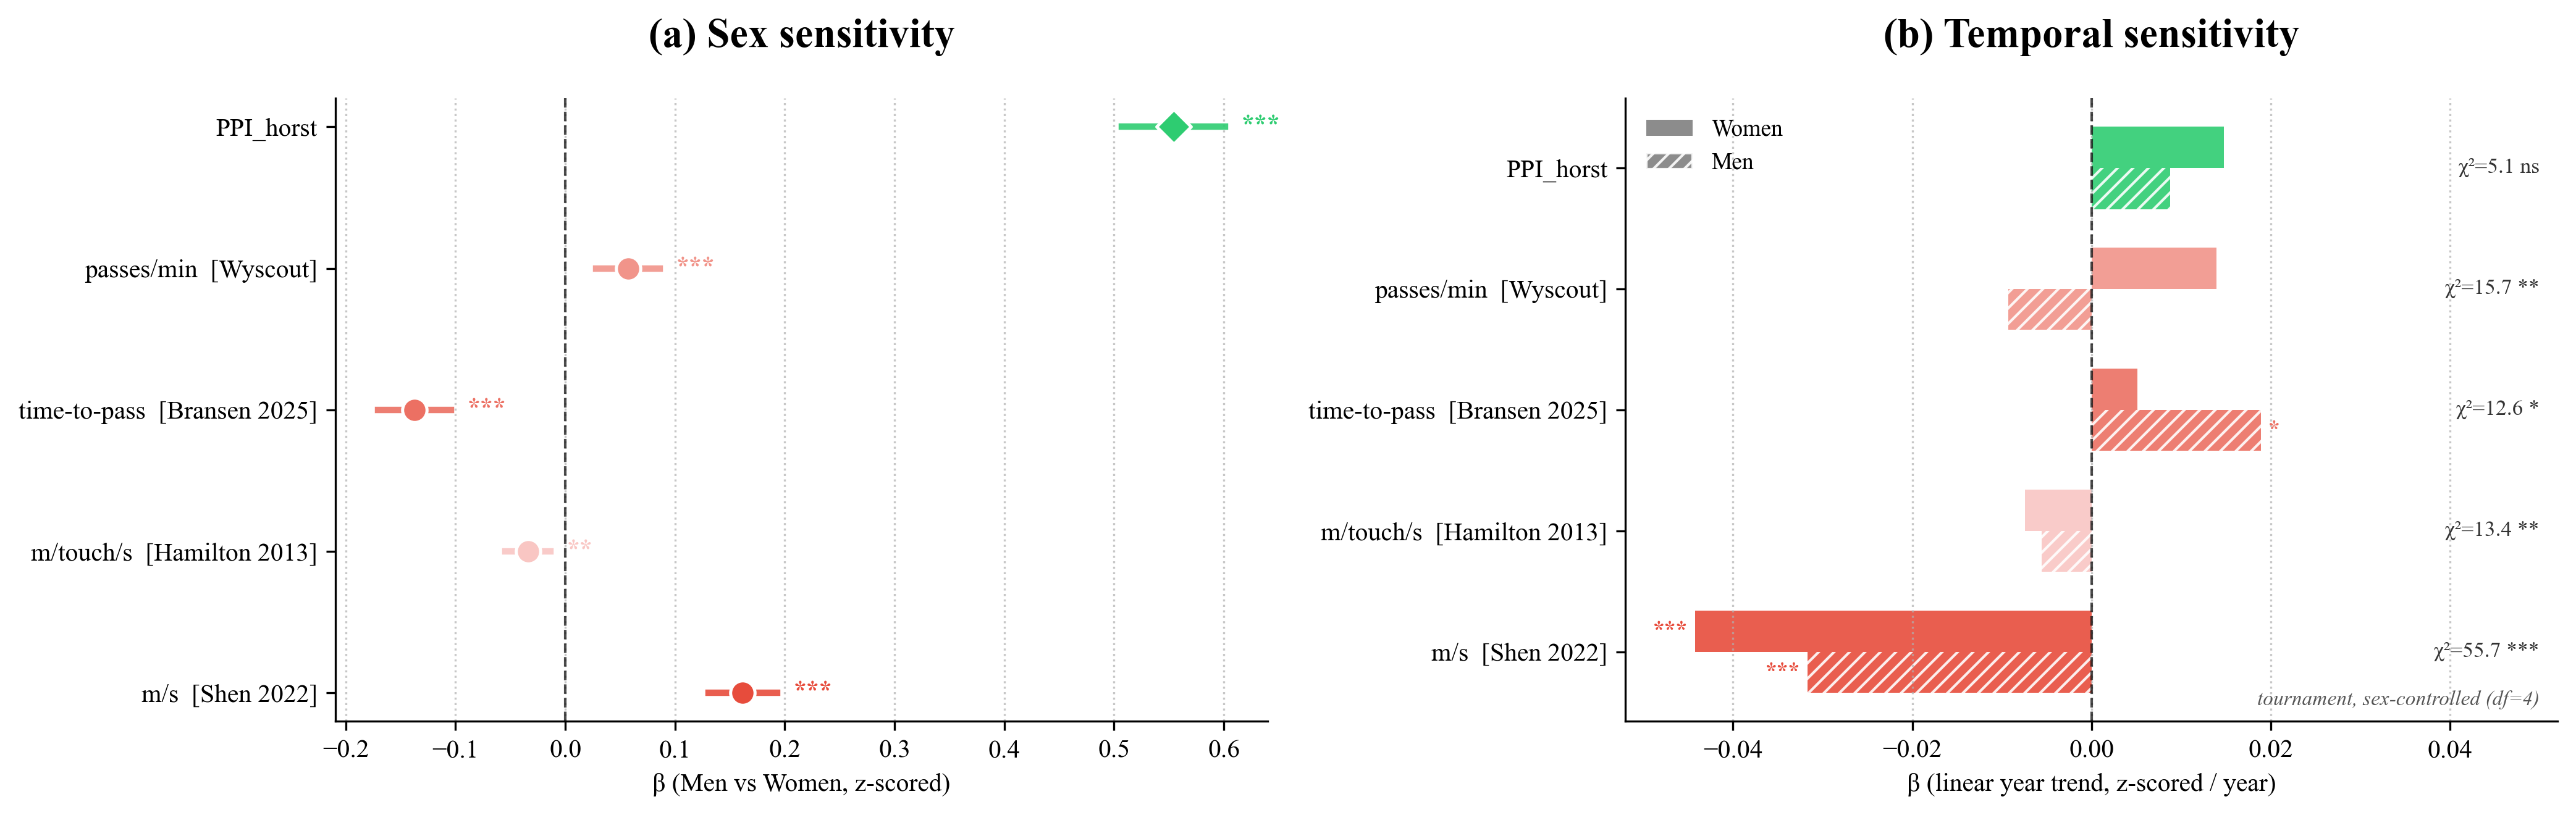

In [10]:
from matplotlib.patches import Patch

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']

METRIC_LABELS = {
    "TI_horst":                              "PPI_horst",
    "baseline_passes_per_min":               "passes/min  [Wyscout]",
    "baseline_time_to_pass":                 "time-to-pass  [Bransen 2025]",
    "baseline_meters_per_touch_per_second":  "m/touch/s  [Hamilton 2013]",
    "baseline_meters_per_second":            "m/s  [Shen 2022]",
}
COLORS = {
    "TI_horst":                              "#2ecc71",
    "baseline_passes_per_min":               "#f1948a",
    "baseline_time_to_pass":                 "#ec7063",
    "baseline_meters_per_touch_per_second":  "#f9c6c3",
    "baseline_meters_per_second":            "#e74c3c",
}

def _sig(p):
    if pd.isna(p): return ""
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=300)
y_pos = np.arange(len(ALL_METRICS))

# ── Panel A: Gender effect (forest plot) ─────────────────────────────────────
ax = axes[0]
for i, m in enumerate(ALL_METRICS):
    row   = gender_res.loc[m]
    color = COLORS[m]
    ax.plot([row["ci_lo"], row["ci_hi"]], [i, i], color=color, lw=2.5, alpha=0.9)
    ax.scatter(row["coef"], i, color=color, edgecolor='white', linewidth=1.2, zorder=5, s=90,
               marker="D" if m == "TI_horst" else "o")
    if row["sig"]:
        ax.text(row["ci_hi"] + 0.015, i, row["sig"], va="center", fontsize=10, color=color, fontweight='bold')

ax.axvline(0, color="black", lw=1, ls="--", alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels([METRIC_LABELS[m] for m in ALL_METRICS])
ax.set_xlabel("β (Men vs Women, z-scored)")
ax.set_title("(a) Sex sensitivity", fontweight='bold', loc='center', fontsize=16, pad=20)
ax.invert_yaxis()
ax.grid(axis='x', linestyle=':', alpha=0.7)

# ── Panel B: Linear year trend by gender (bars) + decoupled tournament χ² (text)
ax = axes[1]
height  = 0.34
x_left, x_right = -0.052, 0.052
x_text  = 0.050                       # right-hand stats column
for i, m in enumerate(ALL_METRICS):
    row = temporal_res.loc[m]
    c   = COLORS[m]
    bw, bm = row["year_slope_Women"], row["year_slope_Men"]
    ax.barh(i - height/2, bw, color=c, alpha=0.9, height=height)                       # Women: solid
    ax.barh(i + height/2, bm, color=c, alpha=0.9, height=height,
            hatch='////', edgecolor='white', linewidth=0.0)                            # Men: hatched
    sw, sm = _sig(row["year_pval_Women"]), _sig(row["year_pval_Men"])
    if sw:
        ax.text(bw + (0.0008 if bw >= 0 else -0.0008), i - height/2, sw,
                va="center", ha="left" if bw >= 0 else "right", fontsize=9, color=c, fontweight='bold')
    if sm:
        ax.text(bm + (0.0008 if bm >= 0 else -0.0008), i + height/2, sm,
                va="center", ha="left" if bm >= 0 else "right", fontsize=9, color=c, fontweight='bold')
    # decoupled (gender-controlled) tournament effect — right-hand stats column
    ax.text(x_text, i, f"χ²={row['lr_chi2_dec']:.1f} {row['lr_sig_dec'] or 'ns'}",
            va="center", ha="right", fontsize=8.5, color="#333333")

ax.text(x_text, 4.4, "tournament, sex-controlled (df=4)",
        va="center", ha="right", fontsize=8, style="italic", color="#555555")

ax.axvline(0, color="black", lw=1, ls="--", alpha=0.7)
ax.set_xlim(x_left, x_right)
ax.set_yticks(y_pos)
ax.set_yticklabels([METRIC_LABELS[m] for m in ALL_METRICS])
ax.set_xlabel("β (linear year trend, z-scored / year)")
ax.set_title("(b) Temporal sensitivity", fontweight='bold', loc='center', fontsize=16, pad=20)
ax.invert_yaxis()
ax.grid(axis='x', linestyle=':', alpha=0.7)
ax.legend(handles=[Patch(facecolor='grey', alpha=0.9, label='Women'),
                   Patch(facecolor='grey', alpha=0.9, hatch='////', edgecolor='white', label='Men')],
          frameon=False, fontsize=9, loc='upper left')

for ax in axes:
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

In [ ]:
# ── Summary table 
summary = pd.DataFrame({
    "label":         [METRIC_LABELS[m] for m in ALL_METRICS],
    "gender_β":      gender_res.reindex(ALL_METRICS)["coef"].round(3),
    "gender_95CI":   [f"[{gender_res.loc[m,'ci_lo']:.3f}, {gender_res.loc[m,'ci_hi']:.3f}]"
                      for m in ALL_METRICS],
    "gender_sig":    gender_res.reindex(ALL_METRICS)["sig"],
    "year_β_Women":  temporal_res.reindex(ALL_METRICS)["year_slope_Women"].round(4),
    "year_β_Men":    temporal_res.reindex(ALL_METRICS)["year_slope_Men"].round(4),
    "LR_χ²_raw":     temporal_res.reindex(ALL_METRICS)["lr_chi2"].round(1),
    "tourn_sig_raw": temporal_res.reindex(ALL_METRICS)["lr_sig"],
    "LR_χ²_dec":     temporal_res.reindex(ALL_METRICS)["lr_chi2_dec"].round(1),
    "tourn_sig_dec": temporal_res.reindex(ALL_METRICS)["lr_sig_dec"],
}, index=ALL_METRICS)

print("=" * 100)
print("SENSITIVITY COMPARISON SUMMARY  (TI_efa vs 4 baselines)")
print("=" * 100)
print(summary.to_string())
print()
print("gender_β      : LMM coefficient (Men − Women) on winsorised z-scored metric; 95% CI in brackets")
print("year_β        : LMM slope per calendar year within gender (linear time trend)")
print("LR_χ²_raw     : likelihood-ratio χ² for tournament vs null ~ 1  (confounded with gender)")
print("LR_χ²_dec     : likelihood-ratio χ² for tournament vs null ~ gender  (gender-decoupled)")


SENSITIVITY COMPARISON SUMMARY  (TI_efa vs 4 baselines)
                                                             label  gender_β       gender_95CI gender_sig  year_β_Women  year_β_Men  LR_χ²_raw tourn_sig_raw  LR_χ²_dec tourn_sig_dec
TI_horst                                                 PPI_horst     0.554    [0.507, 0.601]        ***        0.0148      0.0088      310.1           ***        5.1              
baseline_passes_per_min                      passes/min  [Wyscout]     0.057    [0.028, 0.086]        ***        0.0140     -0.0093       30.3           ***       15.7            **
baseline_time_to_pass                 time-to-pass  [Bransen 2025]    -0.138  [-0.171, -0.104]        ***        0.0051      0.0189       72.2           ***       12.6             *
baseline_meters_per_touch_per_second    m/touch/s  [Hamilton 2013]    -0.034  [-0.055, -0.013]         **       -0.0074     -0.0055       23.8           ***       13.4            **
baseline_meters_per_second        